# ROI_processing

In [12]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os 
import numpy as np
import sys
import seaborn as sns

parent_dir = os.path.abspath(os.path.join(os.getcwd(), '../../src/troutpy_reproducibility'))
# Add parent directory to sys.path
sys.path.append(parent_dir)

from batch_running import *

In [13]:
xrna_df

,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular
0,0.790729,0.209271,0.249124
1,0.523579,0.476421,-0.985812
2,0.677915,0.322085,-0.335995
3,0.723559,0.276441,-0.118016
4,0.716889,0.283111,-0.151116
...,...,...,...
13069,0.970588,0.029412,2.416308
13070,0.968254,0.031746,2.337527
13071,0.925000,0.075000,1.432106
13072,1.000000,0.000000,inf


In [14]:
import os
import pandas as pd

# Define base output directory
base_figures_dir = "/media/sergio/Meninges/troutpy/parameter_tuning/saisnsc/xenium_msbrain_5k/figures"

# Initialize lists to collect data
summary_list = []
xrna_metadata_list = []

# Iterate through each parameter folder
for param_suffix in os.listdir(base_figures_dir):
    folder_path = os.path.join(base_figures_dir, param_suffix)
    folder_path = os.path.join(folder_path, param_suffix)
    summary_path = os.path.join(folder_path, "pipeline_summary.csv")
    xrna_metadata_path = os.path.join(folder_path, "pipeline_xrna_metadata.csv")
    
    if os.path.isfile(summary_path) and os.path.isfile(xrna_metadata_path):
        # Read and annotate summary
        summary_df = pd.read_csv(summary_path)
        summary_df["param_set"] = param_suffix
        summary_list.append(summary_df)
        
        # Read and annotate xrna metadata
        xrna_df = pd.read_csv(xrna_metadata_path)
        proportion=xrna_df[['extracellular_proportion']]
        proportion.columns=[param_suffix]
        xrna_metadata_list.append(proportion)

# Combine all
combined_summary = pd.concat(summary_list, ignore_index=True)
combined_xrna_metadata = pd.concat(xrna_metadata_list,axis=1)


In [15]:
combined_summary

,proportion_of_segmented,proportion_of_extracellular,param_set
0,0.64059,0.270702,bin2_bgf0.2_gk4.0_pt20
1,0.64059,0.211281,bin10_bgf0.2_gk0.0_pt10
2,0.64059,0.259531,bin10_bgf0.2_gk0.0_pt20
3,0.64059,0.211281,bin10_bgf0.2_gk2.0_pt10
4,0.64059,0.259531,bin10_bgf0.2_gk2.0_pt20
5,0.64059,0.190138,bin10_bgf0.2_gk4.0_pt10
6,0.64059,0.242556,bin10_bgf0.2_gk4.0_pt20
7,0.64059,0.211281,bin10_bgf0.4_gk0.0_pt10
8,0.64059,0.259531,bin10_bgf0.4_gk0.0_pt20
9,0.64059,0.211281,bin10_bgf0.4_gk2.0_pt10


##  Combine xrna proportions across runs

In [16]:
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

# filter xrna metadata
combined_xrna_metadata=combined_xrna_metadata[np.sum(combined_xrna_metadata.isna(),axis=1)==0]
# Compute cosine similarity between parameter sets (columns)
cos_sim_matrix = cosine_similarity(combined_xrna_metadata.T)
# Turn it into a labeled DataFrame
cos_sim_df = pd.DataFrame(cos_sim_matrix,index=combined_xrna_metadata.columns,columns=combined_xrna_metadata.columns)


In [17]:
cos_sim_df.shape

(36, 36)

<Figure size 600x500 with 0 Axes>

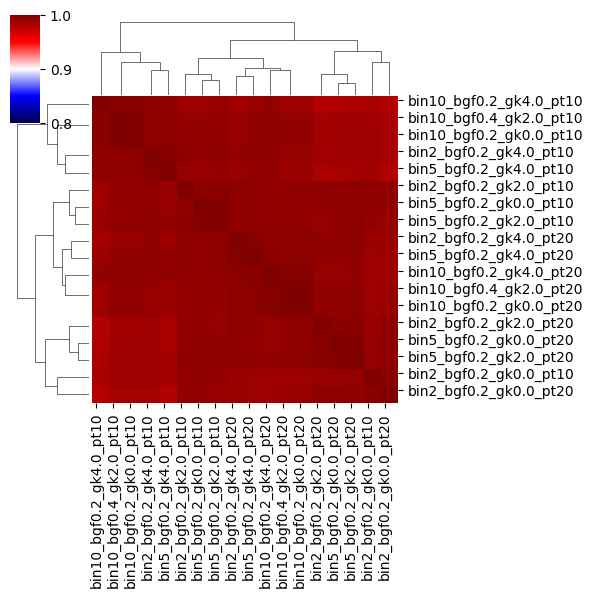

In [18]:
plt.figure(figsize=(6, 5))
sns.clustermap(cos_sim_df,vmin=0.8,vmax=1,cmap='seismic',figsize=(6,6),)

Text(0, 0.5, 'Percentage of extracellular in: bin10_bgf0.2_gk4.0_pt10')

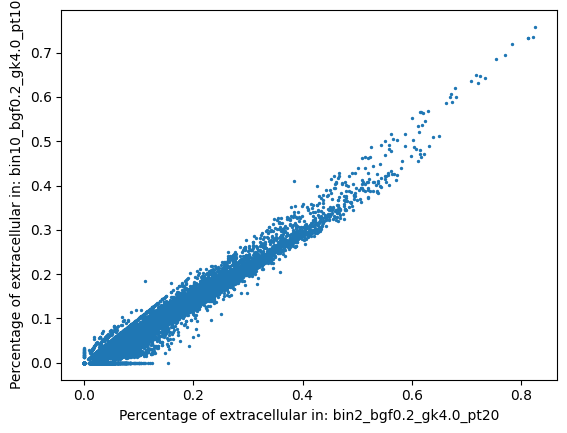

In [42]:
plt.scatter(combined_xrna_metadata.iloc[:,0],combined_xrna_metadata.iloc[:,5],s=2)
plt.xlabel('Percentage of extracellular in: '+combined_xrna_metadata.columns[0])
plt.ylabel('Percentage of extracellular in: '+combined_xrna_metadata.columns[5])

In [21]:
nuclear_housekeeping_genes = [
    "Lmnb1",
    "Ncl",
    "Hnrnpa1",
    "Npm1",
    "Polr2a"
]


combined_xrna_metadata[combined_xrna_metadata.index.isin(nuclear_housekeeping_genes)]

,bin2_bgf0.2_gk4.0_pt20,bin10_bgf0.2_gk0.0_pt10,bin10_bgf0.2_gk0.0_pt20,bin10_bgf0.2_gk2.0_pt10,bin10_bgf0.2_gk2.0_pt20,bin10_bgf0.2_gk4.0_pt10,bin10_bgf0.2_gk4.0_pt20,bin10_bgf0.4_gk0.0_pt10,bin10_bgf0.4_gk0.0_pt20,bin10_bgf0.4_gk2.0_pt10,...,bin5_bgf0.2_gk2.0_pt10,bin5_bgf0.2_gk2.0_pt20,bin5_bgf0.2_gk4.0_pt10,bin5_bgf0.2_gk4.0_pt20,bin5_bgf0.4_gk0.0_pt10,bin5_bgf0.4_gk0.0_pt20,bin5_bgf0.4_gk2.0_pt10,bin5_bgf0.4_gk2.0_pt20,bin5_bgf0.4_gk4.0_pt10,bin5_bgf0.4_gk4.0_pt20


### Plot propotion of exRNA identified

In [22]:
combined_summary['proportion_of_cell_like']=1-combined_summary['proportion_of_segmented']-combined_summary['proportion_of_extracellular']
combined_summary.index=combined_summary['param_set']
combined_summary.pop('param_set')

param_set
bin2_bgf0.2_gk4.0_pt20      bin2_bgf0.2_gk4.0_pt20
bin10_bgf0.2_gk0.0_pt10    bin10_bgf0.2_gk0.0_pt10
bin10_bgf0.2_gk0.0_pt20    bin10_bgf0.2_gk0.0_pt20
bin10_bgf0.2_gk2.0_pt10    bin10_bgf0.2_gk2.0_pt10
bin10_bgf0.2_gk2.0_pt20    bin10_bgf0.2_gk2.0_pt20
bin10_bgf0.2_gk4.0_pt10    bin10_bgf0.2_gk4.0_pt10
bin10_bgf0.2_gk4.0_pt20    bin10_bgf0.2_gk4.0_pt20
bin10_bgf0.4_gk0.0_pt10    bin10_bgf0.4_gk0.0_pt10
bin10_bgf0.4_gk0.0_pt20    bin10_bgf0.4_gk0.0_pt20
bin10_bgf0.4_gk2.0_pt10    bin10_bgf0.4_gk2.0_pt10
bin10_bgf0.4_gk2.0_pt20    bin10_bgf0.4_gk2.0_pt20
bin10_bgf0.4_gk4.0_pt10    bin10_bgf0.4_gk4.0_pt10
bin10_bgf0.4_gk4.0_pt20    bin10_bgf0.4_gk4.0_pt20
bin2_bgf0.2_gk0.0_pt10      bin2_bgf0.2_gk0.0_pt10
bin2_bgf0.2_gk0.0_pt20      bin2_bgf0.2_gk0.0_pt20
bin2_bgf0.2_gk2.0_pt10      bin2_bgf0.2_gk2.0_pt10
bin2_bgf0.2_gk2.0_pt20      bin2_bgf0.2_gk2.0_pt20
bin2_bgf0.2_gk4.0_pt10      bin2_bgf0.2_gk4.0_pt10
bin2_bgf0.4_gk0.0_pt10      bin2_bgf0.4_gk0.0_pt10
bin2_bgf0.4_gk0.0_pt2

In [26]:
combined_summary=combined_summary.sort_values(by='proportion_of_extracellular')

<Axes: ylabel='param_set'>

<Figure size 500x4000 with 0 Axes>

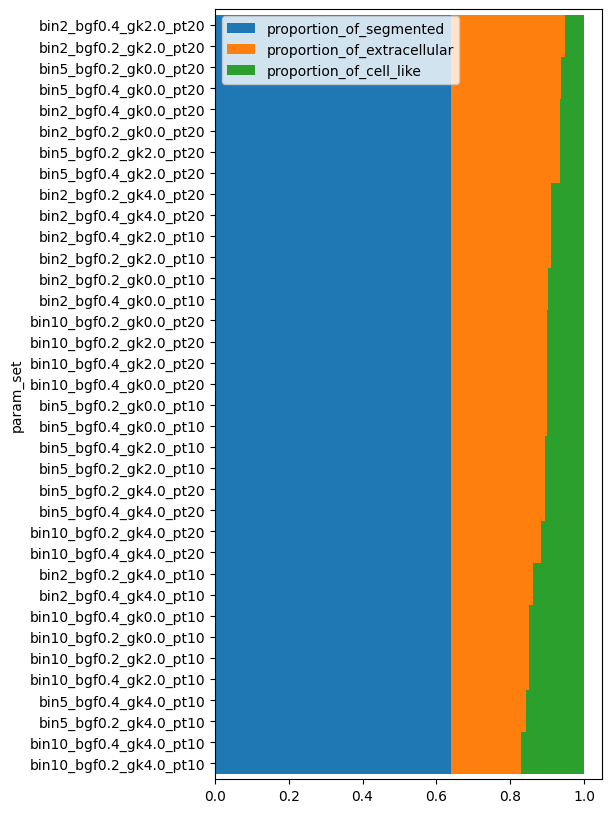

In [34]:
# plot combined summary as bar plot
plt.figure(figsize=(5,40))
combined_summary.plot(kind='barh',stacked=True,width=1,figsize=(5,10))

Text(0, 0.5, 'Assignment')

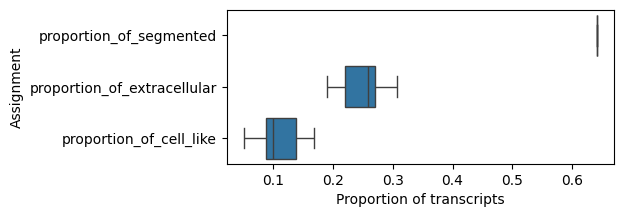

In [56]:
unstacked_combined=combined_summary.unstack().reset_index()
plt.figure(figsize=(5,2))
sns.boxplot(data=unstacked_combined,y='level_0',x=0,color=)
plt.xlabel('Proportion of transcripts')
plt.ylabel('Assignment')

In [ ]:

# Save if needed
combined_summary.to_csv("/media/sergio/Meninges/troutpy/parameter_tuning/combined_summary.csv", index=False)
combined_xrna_metadata.to_csv("/media/sergio/Meninges/troutpy/parameter_tuning/combined_xrna_metadata.csv", index=False)

print("Combined files saved.")
